In [1]:
import gc
import os
import h5py
import pickle
import numpy as np
import pandas as pd
from sklearn import svm
import pandas as pd
import matplotlib.pyplot as plt
from Haldane_anis_supervise_class import *
from partial import *

In [57]:
L = 51 #number of particles must be odd
bond = 70 # resonable amount
keep = [0,1,2,3]
p = partial(L,bond)

In [3]:
dmrg_states = p.generate_dataset()

Starting dataset generation — this step includes both the training and test sets. Please be patient...


Generating train set: 100%|██████████| 4/4 [00:00<00:00, 99.11it/s]


Train_set is generated in 309.68 seconds.


In [58]:
partial_train = p.partial_density_matrix(keep=keep)

Computing partial density matrices started .....
Tracing over training set (4 items)...


Tracing train set: 100%|██████████| 4/4 [00:00<00:00, 1441.34it/s]

Partial density matrices computed in 9.32 seconds.


In [59]:
gram_train = p.gram_train_partial(partial_train=partial_train, keep=keep)

Computing Gram matrix for training set...


Gram Partial Train: 100%|██████████| 16/16 [00:00<00:00, 444.02it/s]

Gram matrix for training set computed in 0.07 seconds.


In [60]:
np.trace(partial_train[0]@partial_train[0]).real**2

0.6058567697487318

In [61]:
gram_train

array([[0.60585677, 0.16135598, 0.03467133, 0.21506631],
       [0.16135598, 0.59374799, 0.23078047, 0.27443415],
       [0.03467133, 0.23078047, 0.29881155, 0.16273533],
       [0.21506631, 0.27443415, 0.16273533, 0.40913532]])

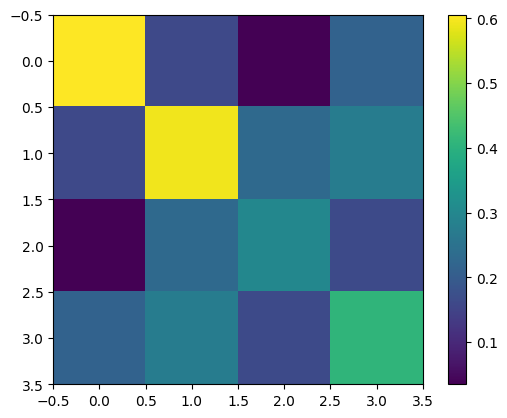

In [62]:
plt.imshow(gram_train)
plt.colorbar()